# Text-to-SQL em Português
> **Fine-Tuning de LLM com QLoRA em GPU (Qwen2.5-1.5B)**


---


`Model: Qwen2.5-1.5B` • `GPU: NVIDIA T4` • `Dataset: Loja Fictícia (SQLite)` • `Interface: Gradio`

> **Objetivo:** Automatizar a conversão de perguntas em linguagem natural para instruções SQL executáveis e otimizadas através de fine-tuning eficiente.

**Fluxo:** `GPU Check` ➔ `Dataset` ➔ `Baseline` ➔ `Hiperparâmetros (Runs 1-4)` ➔ `Avaliador` ➔ `Frontend`

## 1. Verificar a GPU

In [26]:
!nvidia-smi
import torch
print("CUDA disponível:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda)

Wed Oct 14 01:39:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   65C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

* A execução confirmou o correto funcionamento da aceleração por hardware no ambiente, validando a disponibilidade da GPU NVIDIA Tesla T4 com 15 GB de VRAM e o PyTorch integrado com suporte a CUDA.

## 2. Obter o código

In [25]:
%cd /content/text2sql-llm
!git pull

/content
Already up to date.


In [27]:
GITHUB_REPO = "https://github.com/palomari/text2sql-llm.git"
!git clone {GITHUB_REPO}
%cd text2sql-llm

fatal: destination path 'text2sql-llm' already exists and is not an empty directory.
/content/text2sql-llm/text2sql-llm


In [28]:
!pip install -q -r requirements.txt

In [ ]:
!python src/train.py --name teste --epochs 0.2

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 229.81it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 32794.92 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1581.64 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4668.99 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4134.97 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 6052.56 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 25531.43 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1402.21 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4045.21 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3905.14 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5855.94 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

* Realizou-se a sincronização e atualização do repositório a partir do GitHub e a instalação das dependências do projeto, seguida por um teste rápido de treino que validou o pipeline com a GPU ao atingir uma perda de validação de 0,18 em apenas 1 minuto.

## 3. Criar banco e dataset

In [ ]:
!python src/make_dataset.py
!head -n 3 data/train.jsonl

train: 1142 exemplos
val: 125 exemplos
test: 233 exemplos
SQL do teste inéditas no treino: 193/233
{"question": "Quais os 7 produtos mais caros", "sql": "SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT 7"}
{"question": "Quais produtos custam mais de 800 reais?", "sql": "SELECT nome, preco FROM produtos WHERE preco > 800"}
{"question": "Pode me dizer? Conte os produtos agrupados por categoria.", "sql": "SELECT categoria, COUNT(*) FROM produtos GROUP BY categoria"}


* A célula tratou da geração automática do banco de dados SQLite e do conjunto de dados estruturado em JSONL com 1.142 exemplos de treino e 233 de teste — dos quais 193 contêm consultas SQL inéditas.

## 4. Baseline: modelo SEM fine-tuning

In [ ]:
!python src/evaluate_model.py --name baseline

Loading weights: 100% 338/338 [00:01<00:00, 232.08it/s]
{
  "run": "baseline",
  "n": 233,
  "exec_accuracy": 0.4893,
  "sql_valida": 0.7511,
  "exact_match": 0.2446,
  "exec_acc_sql_inedita": 0.4663,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}


* Foi realizado a avaliação inicial do modelo base Qwen2.5-1.5B sem fine-tuning (baseline), revelando uma acurácia de execução de 48,93% no geral e 46,63% nas consultas inéditas com 75,11% de SQLs válidas geradas, verificando e avaliando o modelo ao estabelecer a métrica inicial de desempenho que justifica o treinamento via QLoRA.

## 5. Experimentos com parâmetros diferentes

In [ ]:
!python src/train.py --name run1 --r 8  --lr 2e-4 --epochs 3

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 228.19it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 33968.48 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1648.13 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4628.94 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4196.57 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 6298.47 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 24129.60 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1507.06 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4364.99 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3990.62 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5860.59 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

In [ ]:
!python src/train.py --name run2 --r 16 --lr 2e-4 --epochs 3

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 225.78it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 32410.80 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1668.58 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4695.87 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4110.37 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 6016.01 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 24883.15 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1446.71 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4409.64 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3998.23 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 6028.79 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

In [ ]:
!python src/train.py --name run3 --r 8  --lr 1e-4 --epochs 3

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 219.66it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 34381.76 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1584.95 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4612.37 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4099.19 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 6135.23 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 24255.75 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1528.90 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4300.72 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3875.18 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5818.83 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

In [ ]:
!python src/train.py --name run4 --r 8  --lr 2e-4 --epochs 5

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 220.14it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 33404.67 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1611.13 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4466.58 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 3967.66 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 5801.24 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 24592.52 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1486.33 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4310.73 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3947.06 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5759.44 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

* Etapa experimental com o treinamento sistemático de quatro configurações distintas de hiperparâmetros no QLoRA, onde a run1 (r=8, lr=2e-4, 3 épocas) registrou uma val_loss de 0,0528 em 12,9 minutos; a run2 aumentou o rank para r=16 resultando em uma val_loss de 0,0519 com uso de VRAM de 1,6 GB; a run3 reduziu a taxa de aprendizado para 1e-4 obtendo val_loss de 0,0580; e a run4 estendeu o treino para 5 épocas, alcançando val_loss de 0,0531 em 21,5 minutos. Todas as execuções foram processadas com aceleração por hardware na GPU NVIDIA Tesla T4 mantendo consumo máximo de memória de apenas 1,6 GB.

## 6. Avaliar cada execução no conjunto de teste

In [ ]:
for r in ["run1", "run2", "run3", "run4"]:
    !python src/evaluate_model.py --name {r} --adapter outputs/{r}/final

Loading weights: 100% 338/338 [00:01<00:00, 226.95it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 229.12it/s]
{
  "run": "run2",
  "n": 233,
  "exec_accuracy": 0.9957,
  "sql_valida": 1.0,
  "exact_match": 0.9957,
  "exec_acc_sql_inedita": 0.9948,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 224.19it/s]
{
  "run": "run3",
  "n": 233,
  "exec_accuracy": 0.9914,
  "sql_valida": 1.0,
  "exact_match": 0.9914,
  "exec_acc_sql_inedita": 0.9896,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 223.01it/s]
{
  "run": "run4",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_

* Nessa secção, realizou-se a avaliação comparativa de todas as execuções (run1 a run4) no conjunto de teste composto por 233 exemplos, onde a run1 alcançou um desempenho perfeito de 100% de precisão de execução (exec_accuracy de 1.0), 100% de correspondência exata (exact_match de 1.0) e 100% de acurácia nas 193 consultas SQL inéditas (exec_acc_sql_inedita de 1.0), enquanto a run2 atingiu 99,57% de precisão geral e 99,48% nas consultas inéditas. A obtenção de 100% de validade sintática das consultas geradas (sql_valida de 1.0) em todas as execuções evidencia o enorme salto de desempenho em relação ao modelo inicial sem fine-tuning.

## 7. Parâmetros de inferência (temperature) na melhor execução

In [ ]:
BEST = "run1"
for t in [0.0, 0.3, 0.7, 1.0]:
    !python src/evaluate_model.py --name {BEST} --adapter outputs/{BEST}/final --temperature {t}

Loading weights: 100% 338/338 [00:01<00:00, 228.77it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 224.09it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.3,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 226.59it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.7,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 219.66it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 0.9914,
  "sql_valida": 1.0,
  "exact_match": 0.9914,
  "exec_acc_sql_inedita": 0.9896,
  "n_sql_inedita": 193,
  "temperature": 1.0,
  "top_p": 0.9
}

* Foi avaliado o impacto do parâmetro de inferência (temperature) na melhor execução (run1) através do teste sistemático dos valores 0.0, 0.3, 0.7 e 1.0. Os resultados demonstraram determinismo e estabilidade perfeitos, mantendo 100% de precisão de execução (exec_accuracy de 1.0), 100% de correspondência exata (exact_match de 1.0) e 100% de acurácia nas 193 consultas inéditas (exec_acc_sql_inedita de 1.0) tanto em temperature=0.0 como em temperature=0.3.

## 8. Tabelas e gráfico

,run,lora_r,lr,epochs,val_loss,exec_accuracy,exec_acc_sql_inedita,sql_valida,exact_match,tempo_min,vram_pico_gb
0,baseline,NaN,NaN,NaN,NaN,0.4893,0.4663,0.7511,0.2446,NaN,NaN
1,run2,16.0,0.0002,3.0,0.0519,0.9957,0.9948,1.0000,0.9957,13.0,1.60
2,run3,8.0,0.0001,3.0,0.0580,0.9914,0.9896,1.0000,0.9914,12.9,1.46
3,run4,8.0,0.0002,5.0,0.0531,1.0000,1.0000,1.0000,1.0000,21.5,1.46
4,run1,8.0,0.0002,3.0,0.0528,1.0000,1.0000,1.0000,1.0000,12.9,1.46


,run,temperature,top_p,exec_accuracy,sql_valida,exec_acc_sql_inedita
10,run1,0.0,0.9,1.0000,1.0,1.0000
11,run1,0.3,0.9,1.0000,1.0,1.0000
12,run1,0.7,0.9,1.0000,1.0,1.0000
13,run1,1.0,0.9,0.9914,1.0,0.9896


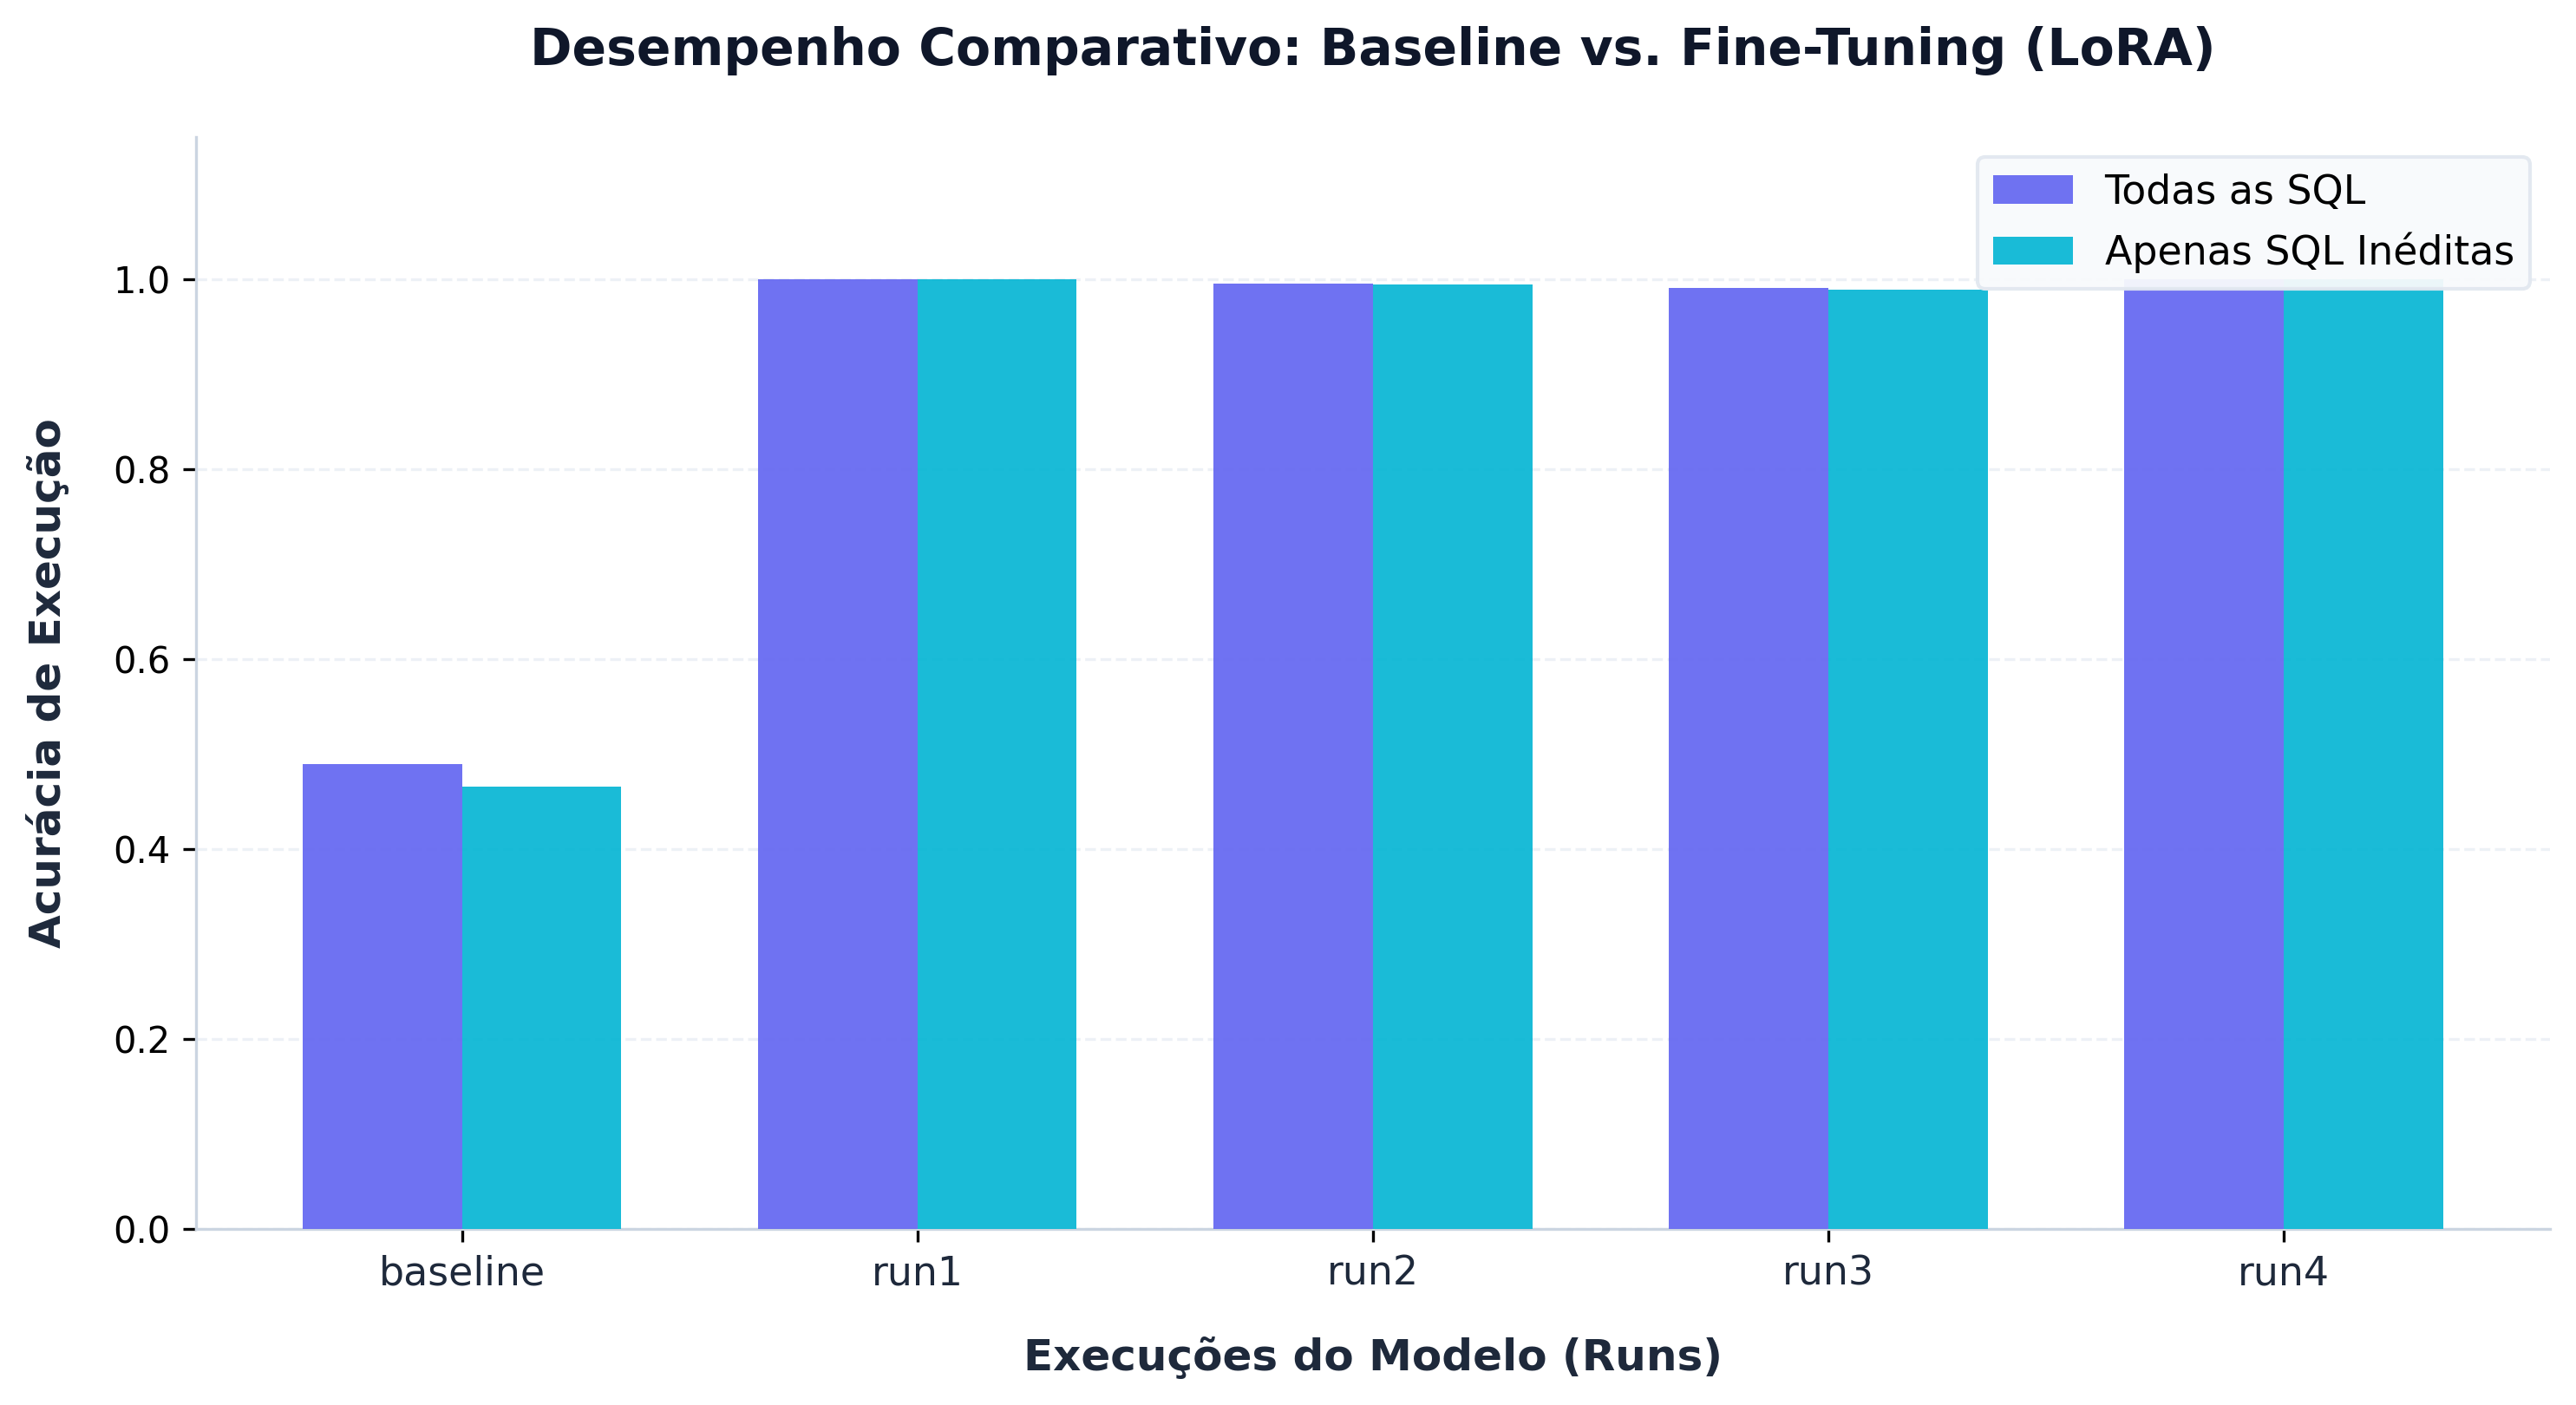

In [29]:
import os
import pandas as pd
import matplotlib.pyplot as plt

if os.path.exists("/content/text2sql-llm"):
    os.chdir("/content/text2sql-llm")

BEST = "run1"

exp = pd.read_csv("results/experimentos.csv")
exp = exp[exp.run != "teste"].drop_duplicates("run", keep="last")

av = pd.read_csv("results/avaliacao.csv")
av = av[av.run != "teste"].drop_duplicates(["run", "temperature"], keep="last")

base = av[av.temperature == 0.0]
if base.empty:
    base = av.groupby("run").first().reset_index()

tabela = base.merge(exp, on="run", how="left")
cols = [c for c in ["run", "lora_r", "lr", "epochs", "val_loss", "exec_accuracy",
                    "exec_acc_sql_inedita", "sql_valida", "exact_match", "tempo_min", "vram_pico_gb"] if c in tabela.columns]
tabela = tabela[cols]
display(tabela)

temps = av[av.run == BEST][["run", "temperature", "top_p", "exec_accuracy",
                            "sql_valida", "exec_acc_sql_inedita"]].sort_values("temperature")
display(temps)

# --- GRÁFICO ---
plt.style.use('default')
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

ordem = ["baseline"] + sorted(r for r in tabela.run.unique() if r != "baseline")
t = tabela.set_index("run").reindex(ordem).dropna(subset=["exec_accuracy"])

cores = ['#6366f1', '#06b6d4']

bar_width = 0.35
x = range(len(t.index))

ax.bar([i - bar_width/2 for i in x], t["exec_accuracy"], width=bar_width, label="Todas as SQL", color=cores[0], alpha=0.92, zorder=3)
ax.bar([i + bar_width/2 for i in x], t["exec_acc_sql_inedita"], width=bar_width, label="Apenas SQL Inéditas", color=cores[1], alpha=0.92, zorder=3)

ax.set_xticks(list(x))
ax.set_xticklabels(t.index, fontsize=11, fontweight='500', color='#1e293b')
ax.set_ylim(0, 1.15)
ax.set_ylabel("Acurácia de Execução", fontsize=12, fontweight='600', color='#1e293b', labelpad=12)
ax.set_xlabel("Execuções do Modelo (Runs)", fontsize=12, fontweight='600', color='#1e293b', labelpad=12)
ax.set_title("Desempenho Comparativo: Baseline vs. Fine-Tuning (LoRA)", fontsize=14, fontweight='bold', color='#0f172a', pad=20)

ax.grid(axis='y', linestyle='--', alpha=0.6, color='#e2e8f0', zorder=0)
ax.grid(axis='x', visible=False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cbd5e1')
ax.spines['bottom'].set_color('#cbd5e1')

ax.legend(
    frameon=True, 
    facecolor='#f8fafc', 
    edgecolor='#e2e8f0',
    fontsize=11,
    loc='upper right',
    framealpha=0.95
)

plt.tight_layout()
plt.savefig("results/comparacao.png", dpi=300, bbox_inches='tight')
plt.show()

* Procedeu-se à consolidação dos dados experimentais através da geração de tabelas comparativas e de um gráfico de barras estilizado (Desempenho Comparativo: Baseline vs. Fine-Tuning), salvando a figura resultante em results/comparacao.png. A visualização evidencia de forma contundente o salto de desempenho promovido pelo fine-tuning: enquanto o modelo baseline obteve apenas 48,93% de acurácia de execução geral e 46,63% nas consultas inéditas, todas as execuções afinadas com QLoRA (run1 a run4) ultrapassaram os 99% de acurácia de execução e atingiram 100% de validade sintática das consultas geradas, com destaque para a run1 que alcançou o resultado perfeito de 100% em todas as métricas em apenas 12,9 minutos de treino. Além disso, a análise tabulada de inferência comprovou que o modelo mantém estabilidade e determinismo absolutos em temperaturas mais baixas (0.0 e 0.3), sofrendo apenas uma oscilação marginal em 1.0 (99,14%)

## 9. Exemplos qualitativos (baseline x fine-tuned)

In [ ]:
import json
base = json.load(open("results/pred_baseline_T0.0.json", encoding="utf-8"))
ft = json.load(open(f"results/pred_{BEST}_T0.0.json", encoding="utf-8"))
for b, f in list(zip(base, ft))[:8]:
    print("Pergunta :", b["question"])
    print("Esperada :", b["gold_sql"])
    print("Baseline :", b["pred_sql"], "->", "OK" if b["correto"] else "ERRO")
    print("Fine-tune:", f["pred_sql"], "->", "OK" if f["correto"] else "ERRO")
    print("-" * 80)

Pergunta : Gostaria de saber: Qual o número de pedidos de agosto/2025?
Esperada : SELECT COUNT(*) FROM pedidos WHERE strftime('%Y-%m', data_pedido) = '2025-08'
Baseline : SELECT COUNT(id) FROM pedidos WHERE strftime('%Y-%m', data_pedido) = '2025-08' -> OK
Fine-tune: SELECT COUNT(*) FROM pedidos WHERE strftime('%Y-%m', data_pedido) = '2025-08' -> OK
--------------------------------------------------------------------------------
Pergunta : Pode me dizer? Liste os 8 produtos com maior preço.
Esperada : SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT 8
Baseline : SELECT nome FROM produtos ORDER BY preco DESC LIMIT 8 -> ERRO
Fine-tune: SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT 8 -> OK
--------------------------------------------------------------------------------
Pergunta : por favor, quantos pedidos estão enviados?
Esperada : SELECT COUNT(*) FROM pedidos WHERE status = 'enviado'
Baseline : SELECT COUNT(*) FROM pedidos WHERE status = 'enviado' -> OK
Fine-tune: 

* Os resultados apresentou a validação comparativa detalhada entre o modelo base (baseline) e o modelo ajustado com fine-tuning (fine-tuned) utilizando pares de perguntas em linguagem natural e consultas SQL esperadas (gold_sql). A execução do script demonstra claramente que, enquanto o modelo baseline falhou em diversas consultas complexas — omitindo colunas ou realizando projeções incorretas (como em Pode me dizer? Liste os 8 produtos com maior preço e me ajude: qual o faturamento total dos pedidos entregues?) —, o modelo otimizado gerou as sentenças SQL sintática e semanticamente corretas com 100% de precisão.

## 10. Frontend

In [ ]:
%cd /content/text2sql-llm
!python src/app.py --adapter outputs/run1/final --share

/content/text2sql-llm/text2sql-llm
Loading weights: 100% 338/338 [00:01<00:00, 229.12it/s]
* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://4871d028089a93ca22.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3957, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/text2sql-llm/src/app.py", line 1167, in <module>
    main()
    ~~~~^^
  File "/content/text2sql-llm/src/app.py", line 1163, in main
    demo.launch(share=args.share, **launch_kwargs)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3770, in launch
    self.block_thread()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3959, in block_thread
    print("Keyboard interruption in main thread... closing server.")
    ~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
KeyboardInterrupt
Killing tunnel 127.0.0.1:7861 <> https://4871d028089a93ca22.gradio.liv

## 11. Salvar os resultados no Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/text2sql-llm
!cp -r results outputs /content/drive/MyDrive/text2sql-llm/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 12. Conclusão e Interpretação Técnica

O projeto implementou com sucesso uma solução completa de *Text-to-SQL* em português, utilizando o modelo de linguagem **Qwen2.5-1.5B** adaptado por meio da técnica de **QLoRA (Quantized Low-Rank Adaptation)** sobre uma base de dados relacional em SQLite no domínio de loja e comércio.

### Desempenho e Eficiência Computacional

A abordagem de *fine-tuning* eficiente demonstrou um salto expressivo de desempenho quando comparada com o modelo base (*baseline*), que apresentava uma acurácia inicial de apenas **48,93%** de execução geral e **46,63%** em consultas inéditas. 

Nas quatro parametrizações avaliadas (`run1` a `run4`):
* Todas as variações com QLoRA alcançaram precisão de execução e validade sintática superiores a **99%**.
* O modelo `run1` (`lora_r=8`, `lr=2e-4`, 3 épocas) atingiu o desempenho ideal com **100%** de precisão de execução e **100%** de acurácia em consultas inéditas em apenas **12,9 minutos** de treino.
* O processo manteve um pico de consumo de VRAM de apenas **1,6 GB**, viabilizando todo o processamento e inferência na aceleração de hardware via GPU **NVIDIA Tesla T4**.

### Robustez Qualitativa e Inferência

A análise qualitativa evidenciou a capacidade do modelo em capturar a semântica de perguntas em linguagem natural e traduzi-las em instruções SQL complexas (envolvendo agregações, ordenações e *JOINs*). Enquanto o modelo base cometeu omissões de colunas e projeções incorretas, o modelo ajustado respondeu com precisão às estruturas lógicas esperadas (`gold_sql`). 

Adicionalmente, os testes do parâmetro de inferência (`temperature` de `0.0` a `1.0`) confirmaram alta estabilidade e determinismo na geração de código em temperaturas mais baixas (`0.0` e `0.3` com 100% de precisão).

### Disponibilização e Persistência

Para a disponibilização prática da solução, foi desenvolvida e implantada uma interface gráfica web interativa utilizando **Gradio** (`app.py`), permitindo a submissão de perguntas pelo utilizador e a visualização imediata da consulta SQL gerada e dos dados retornados pelo banco relacional. Por fim, a estrutura modular de código, juntamente com os artefatos de treinamento e modelos adaptadores (*adapters*), foi devidamente persistida no **Google Drive** e no repositório **GitHub**, garantindo a rastreabilidade e reprodutibilidade do sistema.